In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [20]:
df = pd.read_csv("data.csv")

In [21]:
tv = df["TV"]
sales = df["sales"]

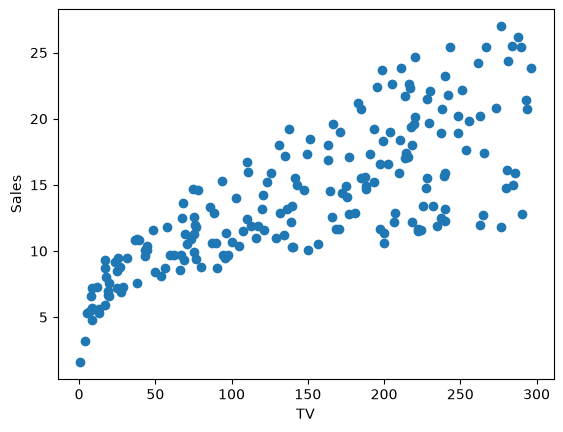

In [22]:
plt.scatter(tv, sales)
plt.xlabel("TV")
plt.ylabel("Sales")
plt.show()

In [23]:
epoch = 1000000
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)
learningRate = 0.001

info = np.zeros((4, epoch))

tv_mean = tv.mean()
tv_std = tv.std(ddof=0)
sales_mean = sales.mean()
sales_std = sales.std(ddof=0)

tv_zscore = (tv - tv_mean) / tv_std
sales_zscore = (sales - sales_mean) / sales_std

y = torch.tensor(sales_zscore.to_numpy(), dtype=torch.float32)
x = torch.tensor(tv_zscore.to_numpy(), dtype=torch.float32)
for i in range(epoch):
    yhat = x * w + b
    loss = ((y - yhat) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= learningRate * w.grad
        b -= learningRate * b.grad
    w.grad.zero_()
    b.grad.zero_()
    info[0][i] = i + 1
    info[1][i] = w.item()
    info[2][i] = b.item()
    info[3][i] = loss.item()

w_original = w.item() * (sales_std / tv_std)
b_original = b.item() * sales_std + sales_mean - w_original * tv_mean

Text(0, 0.5, 'Loss')

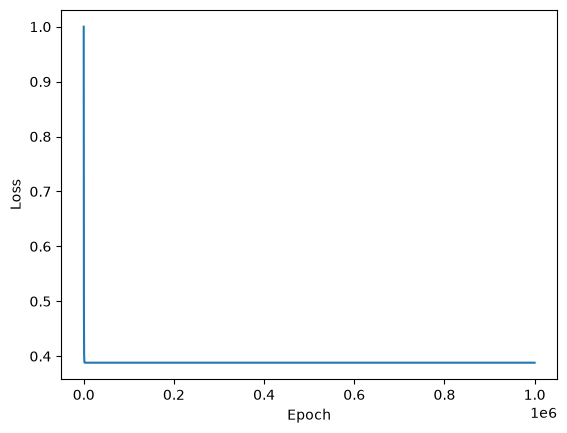

In [24]:
plt.plot(info[0], info[3])
plt.xlabel("Epoch")
plt.ylabel("Loss")

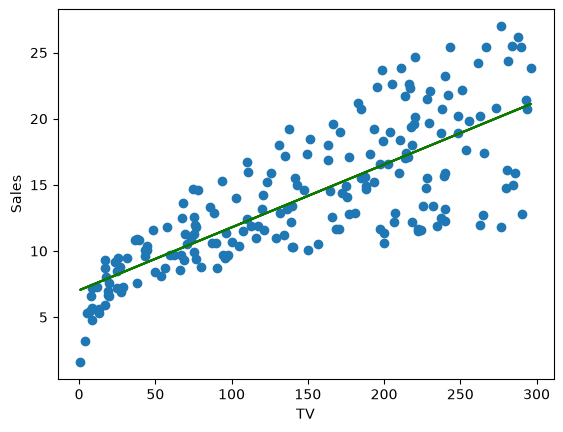

Sklearn w: 0.047536640433019736
Sklearn b: 7.0325935491276965
My w (original scale): 0.04753573800127328
My b (original scale): 7.032726167453736
My w: 0.782209575176239
My b: -1.4890110477949747e-08
My loss:      10.512653350830078
Sklearn loss: 10.512652397155762


In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(tv.values.reshape(-1, 1), sales.values)

sklearn_yhat = torch.tensor(
    model.predict(tv.values.reshape(-1, 1)),
    dtype=torch.float32
)


x_original = torch.tensor(tv.to_numpy(), dtype=torch.float32)
y_original = torch.tensor(sales.to_numpy(), dtype=torch.float32)
x_zscore = (x_original - x_original.mean()) / x_original.std()
yhat_zscore = x_zscore * w + b
yhat_original = yhat_zscore * sales.std() + sales.mean()

plt.scatter(tv, sales)
plt.plot(tv, yhat_original.detach().numpy(), color="red")
plt.plot(tv, sklearn_yhat.numpy(), color="green")
plt.xlabel("TV")
plt.ylabel("Sales")
plt.show()

print("Sklearn w:", model.coef_[0])
print("Sklearn b:", model.intercept_)
print("My w (original scale):", w_original)
print("My b (original scale):", b_original)
print("My w:", w.item())
print("My b:", b.item())

myloss = ((y_original - yhat_original) ** 2).mean()
sklearnloss = ((y_original - sklearn_yhat) ** 2).mean()

print("My loss:     ", myloss.item())
print("Sklearn loss:", sklearnloss.item())